# Проект 3. Уровень дохода (adult.csv)

**Заказчик — банк.** По модели решают, кому предложить премиальную кредитную карту.
Предложить человеку с низким доходом — отказ и расходы на рассылку. Пропустить человека с высоким доходом — упущенная выгода. По стоимости ошибки сопоставимы.

**Данные:** `adult.csv`, 32 561 человек (перепись населения США), цель `income`: `>50K` или `<=50K`.

Структура ноутбука (по слайду «Задачи по блокам»):

| Блок | Что делаем |
|---|---|
| **А. Базовый** | пропуски `?`, split, импутация, OHE + StandardScaler, логистическая регрессия, confusion matrix |
| **Б. Основной** | EDA, Pipeline + ColumnTransformer без утечек, 2 модели на StratifiedKFold(5), метрика под заказчика и порог, вывод |
| **В. Продвинутый** | все проблемы данных и утечки, методы против дисбаланса внутри CV, анализ ошибок по группам, ограничения (допустимость признаков) |

> Принцип на весь ноутбук: **всё, что «учится» (импутер, скейлер, энкодер, порог, ресемплинг), учится только на train**, а отложенный тест используется для итоговой оценки.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42

# Ноутбук лежит в Machine_Learning/modul1, данные — в Machine_Learning/data
CANDIDATES = [Path("../data/adult.csv"), Path("data/adult.csv"), Path("adult.csv"), Path("../../data/adult.csv")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("adult.csv не найден: положите его в Machine_Learning/data/")
print("Данные:", DATA_PATH.resolve())

Данные: /home/claude/Machine_Learning/data/adult.csv


---
# Блок А. Базовый

## А.1. Загрузка. В файле пропуски записаны как `?`, поэтому `na_values="?"`

In [2]:
# Пропуски в файле записаны символом "?", pandas сам их не распознает -> говорим явно
df_raw = pd.read_csv(DATA_PATH, na_values="?", skipinitialspace=True)

df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [3]:
# Пропуски по столбцам: количество и доля
miss = df_raw.isna().sum()
miss_table = pd.DataFrame({"пропусков": miss, "доля, %": (miss / len(df_raw) * 100).round(2)})
display(miss_table[miss_table["пропусков"] > 0])

# Доля классов целевой переменной
display(df_raw["income"].value_counts().to_frame("кол-во").join(
    df_raw["income"].value_counts(normalize=True).round(4).rename("доля")))

,пропусков,"доля, %"
workclass,1836,5.64
occupation,1843,5.66
native.country,583,1.79


,кол-во,доля
income,,
<=50K,24720,0.7592
>50K,7841,0.2408


## А.2. `income` -> 0/1 и разбиение **до любой обработки**

`train_test_split(test_size=0.2, stratify=y, random_state=42)`. Делим сразу, чтобы импутер, скейлер и энкодер «не видели» тест.

In [4]:
# 1 = ">50K", 0 = "<=50K"
y_a = (df_raw["income"] == ">50K").astype(int)
X_a = df_raw.drop(columns="income")

Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_a, y_a, test_size=0.2, stratify=y_a, random_state=RANDOM_STATE)

print("train:", Xa_train.shape, "| test:", Xa_test.shape)
print("доля >50K  train: %.4f | test: %.4f" % (ya_train.mean(), ya_test.mean()))

train: (26048, 14) | test: (6513, 14)
доля >50K  train: 0.2408 | test: 0.2407


## А.3. Импутация `workclass`, `occupation`, `native.country`

`SimpleImputer(strategy="most_frequent")`, **`fit` только на train**, на тесте только `transform`.

In [5]:
cols_impute = ["workclass", "occupation", "native.country"]

imputer = SimpleImputer(strategy="most_frequent")
Xa_train, Xa_test = Xa_train.copy(), Xa_test.copy()

Xa_train[cols_impute] = imputer.fit_transform(Xa_train[cols_impute])   # учимся на train
Xa_test[cols_impute] = imputer.transform(Xa_test[cols_impute])         # на тесте только применяем

print("Чем заполняли (мода train):", dict(zip(cols_impute, imputer.statistics_)))
print("Пропусков осталось: train =", int(Xa_train.isna().sum().sum()), "| test =", int(Xa_test.isna().sum().sum()))

Чем заполняли (мода train): {'workclass': 'Private', 'occupation': 'Prof-specialty', 'native.country': 'United-States'}
Пропусков осталось: train = 0 | test = 0


## А.4. OneHotEncoder для текстовых столбцов, StandardScaler для числовых

In [6]:
cat_cols_a = Xa_train.select_dtypes(include="object").columns.tolist()
num_cols_a = Xa_train.select_dtypes(exclude="object").columns.tolist()
print("Текстовые:", cat_cols_a)
print("Числовые: ", num_cols_a)

# handle_unknown="ignore": если в тесте встретится категория, которой не было в train, строка из нулей, а не ошибка
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
scaler = StandardScaler()

# fit только на train
Xa_train_cat = ohe.fit_transform(Xa_train[cat_cols_a])
Xa_train_num = scaler.fit_transform(Xa_train[num_cols_a])
# на тесте только transform
Xa_test_cat = ohe.transform(Xa_test[cat_cols_a])
Xa_test_num = scaler.transform(Xa_test[num_cols_a])

Xa_train_final = np.hstack([Xa_train_num, Xa_train_cat])
Xa_test_final = np.hstack([Xa_test_num, Xa_test_cat])
print("Итоговая матрица признаков: train", Xa_train_final.shape, "| test", Xa_test_final.shape)

Текстовые: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']
Числовые:  ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']


Итоговая матрица признаков: train (26048, 105) | test (6513, 105)


## А.5. LogisticRegression, accuracy, confusion_matrix. Какую долю людей с доходом >50K нашла модель?

Accuracy: 0.8558   (всегда '<=50K' дало бы 0.7593)
Confusion matrix:
[[4606  339]
 [ 600  968]]

Найдено людей с доходом >50K: 968 из 1568  ->  доля (recall) = 61.7%
Из тех, кого модель назвала '>50K', верно: 74.1% (precision)


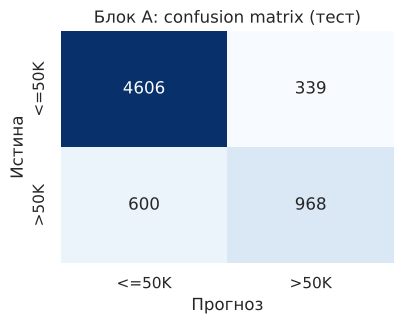

In [7]:
log_reg_a = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg_a.fit(Xa_train_final, ya_train)
pred_a = log_reg_a.predict(Xa_test_final)

acc_a = accuracy_score(ya_test, pred_a)
cm_a = confusion_matrix(ya_test, pred_a)          # строки = истина, столбцы = прогноз
tn, fp, fn, tp = cm_a.ravel()
recall_a = tp / (tp + fn)                         # доля найденных среди всех реальных >50K
precision_a = tp / (tp + fp)                      # доля реальных >50K среди тех, кому «предложили»
baseline_acc = 1 - ya_test.mean()                 # accuracy «модели», которая всегда говорит "<=50K"

print(f"Accuracy: {acc_a:.4f}   (всегда '<=50K' дало бы {baseline_acc:.4f})")
print(f"Confusion matrix:\n{cm_a}")
print(f"\nНайдено людей с доходом >50K: {tp} из {tp + fn}  ->  доля (recall) = {recall_a:.1%}")
print(f"Из тех, кого модель назвала '>50K', верно: {precision_a:.1%} (precision)")

fig, ax = plt.subplots(figsize=(4.2, 3.4))
sns.heatmap(cm_a, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["<=50K", ">50K"], yticklabels=["<=50K", ">50K"])
ax.set_xlabel("Прогноз"); ax.set_ylabel("Истина"); ax.set_title("Блок А: confusion matrix (тест)")
plt.tight_layout(); plt.show()

### Вывод по блоку А

- **Accuracy = 0.856** на тесте. Кажется, что неплохо, но модель «всем ставим `<=50K`» даёт **0.759**, то есть выигрыш над тривиальным ответом всего около 10 п.п.
- **Матрица ошибок:** TN = 4606, FP = 339, FN = 600, TP = 968.
- **Какую долю людей с доходом >50K нашла модель:** 968 из 1568, то есть **61,7%** (это recall по классу `>50K`). Остальные **38%** состоятельных клиентов банк бы пропустил (упущенная выгода).
- Из тех, кому модель «предложила» карту, действительно с доходом >50K оказались **74,1%** (precision); у остальных 26% — отказ и расходы на рассылку.
- Почему accuracy недостаточно: классы несбалансированы (76% / 24%), и accuracy в основном отражает точность по большому классу. Для банка важны оба вида ошибок, поэтому в блоке Б переходим на F1 по классу `>50K` и подбираем порог.

Что здесь сделано правильно: split до любой обработки, импутер, энкодер и скейлер обучены только на train (`fit`), на тесте только `transform`.
Что здесь упрощено (исправляем в Б): дубликаты не удалены (7 тестовых строк имеют точную копию в train), `fnlwgt` и дублирующий `education` оставлены, порог 0.5 не подбирался.

---
# Блок Б. Основной

## Б.0. Подготовка: дубликаты убираем **до** разбиения

В данных есть полностью одинаковые строки. Если оставить дубликаты, одна и та же строка может попасть и в train, и в test, и тест перестанет быть «незнакомым». Поэтому сначала считаем дубликаты на всём датасете (это не использует целевую переменную как признак для обучения), удаляем, и только потом делим.

In [8]:
df = df_raw.copy()
n_dup = df.duplicated().sum()
print("Полных дубликатов строк:", n_dup, f"({n_dup / len(df):.2%})")

# Сколько тестовых строк блока А были «подсмотрены» в train (точные копии)?
leak_a = X_a.loc[Xa_test.index].merge(X_a.loc[Xa_train.index].drop_duplicates(), how="inner").shape[0]
print("В блоке А (без дедупликации) тестовых строк, у которых есть точная копия в train:", leak_a)

df = df.drop_duplicates().reset_index(drop=True)
print("После удаления:", df.shape)

y = (df["income"] == ">50K").astype(int)
X = df.drop(columns="income")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, "| test:", X_test.shape, "| доля >50K: %.4f / %.4f" % (y_train.mean(), y_test.mean()))

Полных дубликатов строк: 24 (0.07%)
В блоке А (без дедупликации) тестовых строк, у которых есть точная копия в train: 7
После удаления: (32537, 15)
train: (26029, 14) | test: (6508, 14) | доля >50K: 0.2409 / 0.2409


## Б.1. EDA (только по train)

Всё, что связано с целевой переменной, смотрим **только на train**, чтобы выводы о признаках не опирались на тест.

### Пропуски, в том числе скрытые

In [9]:
eda = X_train.copy()
eda["income"] = y_train.values

# 1) явные пропуски (бывшие "?")
m = eda.drop(columns="income").isna().sum()
m = pd.DataFrame({"пропусков": m, "доля, %": (m / len(eda) * 100).round(2)})
display(m[m["пропусков"] > 0])

# 2) скрытые пропуски: заглушки в тексте (пробелы, "?", "unknown", "none") ...
obj_cols = eda.select_dtypes("object").columns.drop("income", errors="ignore")
hidden_txt = {c: int(eda[c].astype(str).str.strip().str.lower().isin(["", "?", "unknown", "none", "nan", "n/a"]).sum())
              for c in obj_cols}
print("Текстовые заглушки (кроме NaN):", {k: v for k, v in hidden_txt.items() if v} or "не найдены")

# 3) ... и числовые «заглушки» (top-coding, нулевые значения вместо «нет данных»)
print()
print("capital.gain == 99999:", int((eda["capital.gain"] == 99999).sum()),
      "| доля >50K среди них: %.2f" % eda.loc[eda["capital.gain"] == 99999, "income"].mean())
print("hours.per.week == 99: ", int((eda["hours.per.week"] == 99).sum()), "(верхняя граница шкалы)")
print("age == 90:            ", int((eda["age"] == 90).sum()), "(возраст «обрезан» на 90)")
print("capital.gain == 0: %.1f%% | capital.loss == 0: %.1f%%" % (
    (eda["capital.gain"] == 0).mean() * 100, (eda["capital.loss"] == 0).mean() * 100))

,пропусков,"доля, %"
workclass,1479,5.68
occupation,1484,5.70
native.country,455,1.75


Текстовые заглушки (кроме NaN): не найдены

capital.gain == 99999: 124 | доля >50K среди них: 1.00
hours.per.week == 99:  69 (верхняя граница шкалы)
age == 90:             36 (возраст «обрезан» на 90)
capital.gain == 0: 91.6% | capital.loss == 0: 95.4%


### Выбросы

,выбросов по IQR,"доля, %",min,median,max
age,187,0.7,17,37.0,90
fnlwgt,785,3.0,12285,178142.0,1484705
education.num,952,3.7,1,10.0,16
capital.gain,2174,8.4,0,0.0,99999
capital.loss,1204,4.6,0,0.0,4356
hours.per.week,7241,27.8,1,40.0,99


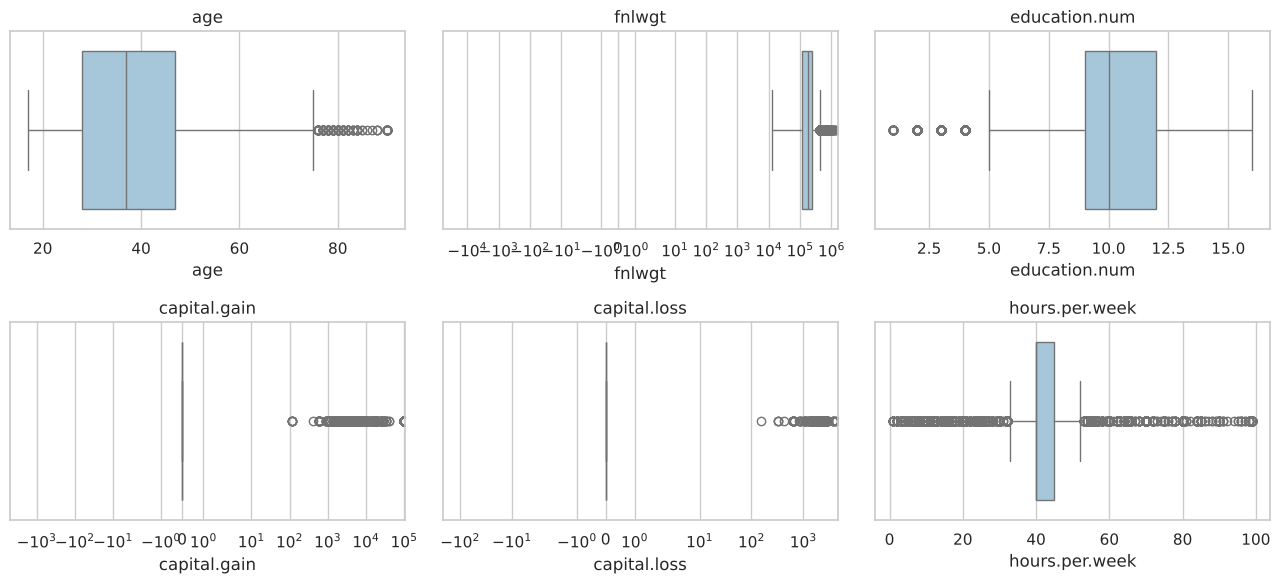

In [10]:
num_cols_eda = ["age", "fnlwgt", "education.num", "capital.gain", "capital.loss", "hours.per.week"]

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

out_tbl = pd.DataFrame({
    "выбросов по IQR": {c: iqr_outliers(eda[c]) for c in num_cols_eda},
    "доля, %": {c: round(iqr_outliers(eda[c]) / len(eda) * 100, 1) for c in num_cols_eda},
    "min": eda[num_cols_eda].min(), "median": eda[num_cols_eda].median(), "max": eda[num_cols_eda].max()})
display(out_tbl)

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), num_cols_eda):
    sns.boxplot(x=eda[c], ax=ax, color="#9ecae1")
    ax.set_title(c)
    if c in ("capital.gain", "capital.loss", "fnlwgt"):
        ax.set_xscale("symlog")
plt.tight_layout(); plt.show()

Как читать: у `capital.gain` и `capital.loss` почти все значения нули, а «выбросы» — это реальные ненулевые люди, а не ошибки, поэтому не удаляем их, а гасим перекос логарифмом `log1p`. `age = 90` и `hours = 99` — «обрезанные» верхние значения (top-coding), оставляем: их мало и они не искажают модель.

### Подозрительные и дублирующие признаки

In [11]:
# 1) education и education.num: одно и то же в двух видах?
pairs = eda.groupby("education")["education.num"].nunique()
print("education -> education.num однозначно:", bool((pairs == 1).all()),
      "| число уровней:", eda["education"].nunique(), "=", eda["education.num"].nunique())

# 2) relationship и sex / marital.status перекрываются
display(pd.crosstab(eda["relationship"], eda["sex"], normalize="index").round(2))

# 3) сила связи с целевой: взаимная информация (универсальна для чисел и категорий)
tmp = eda.drop(columns="income").copy()
for c in tmp.select_dtypes("object"):
    tmp[c] = tmp[c].fillna("MISSING").astype("category").cat.codes
discrete = [tmp[c].dtype.kind != "f" and c not in ("age", "fnlwgt", "capital.gain", "capital.loss", "hours.per.week") for c in tmp]
mi = pd.Series(mutual_info_classif(tmp, eda["income"], discrete_features=discrete, random_state=RANDOM_STATE),
               index=tmp.columns).sort_values(ascending=False)
display(mi.round(4).to_frame("взаимная информация с income").T)

education -> education.num однозначно: True | число уровней: 16 = 16


sex,Female,Male
relationship,,
Husband,0.00,1.00
Not-in-family,0.47,0.53
Other-relative,0.44,0.56
Own-child,0.44,0.56
Unmarried,0.77,0.23
Wife,1.00,0.00


,relationship,marital.status,capital.gain,age,education.num,education,occupation,hours.per.week,capital.loss,fnlwgt,sex,workclass,race,native.country
взаимная информация с income,0.1142,0.1076,0.084,0.0688,0.0649,0.0649,0.0635,0.0459,0.0371,0.0285,0.0269,0.0148,0.0059,0.0057


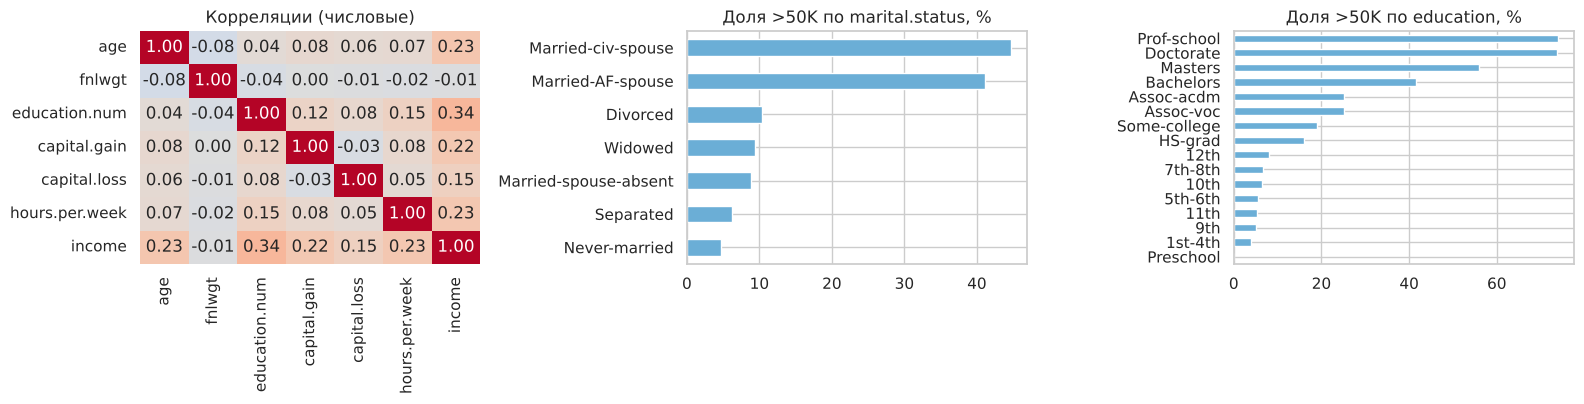

In [12]:
# 4) Корреляция числовых + связь с целевой по категориям
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.heatmap(eda[num_cols_eda + ["income"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], cbar=False)
axes[0].set_title("Корреляции (числовые)")
for ax, c in zip(axes[1:], ["marital.status", "education"]):
    (eda.groupby(c)["income"].mean().sort_values().mul(100)).plot.barh(ax=ax, color="#6baed6")
    ax.set_title(f"Доля >50K по {c}, %"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Что нашли в EDA и что с этим делаем:**

| Находка | Что делаем |
|---|---|
| `?` в `workclass`, `occupation`, `native.country` (около 6% и 2%) | импутация модой **внутри Pipeline** (fit только на train) |
| `education` и `education.num` кодируют одно и то же (16 уровней, соответствие 1:1) | **удаляем `education`**, оставляем порядковый `education.num` |
| `fnlwgt` — статистический вес записи в переписи, это не характеристика человека; взаимная информация с целью низкая (около 0.03, одна из самых слабых), абляция на CV ниже подтверждает | **удаляем `fnlwgt`** |
| `capital.gain`, `capital.loss`: >90% нулей, тяжёлый хвост, 99999 — «потолок» | `log1p` + масштабирование, строки не удаляем |
| 24 полных дубликата | удалены до разбиения (Б.0) |
| `relationship` пересекается с `sex` и `marital.status` | оставляем, но обсуждаем в блоке В (прокси защищённых признаков) |

Решения принимаем по EDA на train, проверяем ниже на кросс-валидации (абляция `fnlwgt` + `education`).

## Б.2. Pipeline + ColumnTransformer без утечек

Вся предобработка внутри `Pipeline`: при каждом `fit` на фолде импутер, скейлер и энкодер обучаются **только на обучающей части фолда**. Столбцы, не перечисленные в `ColumnTransformer` (`fnlwgt`, `education`), отбрасываются через `remainder="drop"`.

In [13]:
NUM = ["age", "education.num", "hours.per.week"]          # обычные числовые
MONEY = ["capital.gain", "capital.loss"]                  # перекошенные: сначала log1p
CAT = ["workclass", "marital.status", "occupation", "relationship", "race", "sex", "native.country"]
DROPPED = ["fnlwgt", "education"]                         # бесполезные / дублирующие (см. таблицу выше)

def make_preprocessor(num=NUM, money=MONEY, cat=CAT):
    parts = []
    if num:
        parts.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                                       ("sc", StandardScaler())]), num))
    if money:
        parts.append(("money", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                         ("sc", StandardScaler())]), money))
    if cat:
        parts.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat))
    return ColumnTransformer(parts, remainder="drop")

def make_pipe(model, **kw):
    return Pipeline([("prep", make_preprocessor(**kw)), ("clf", model)])

models = {
    "LogisticRegression": make_pipe(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "RandomForest": make_pipe(RandomForestClassifier(n_estimators=120, min_samples_leaf=3, max_depth=18, n_jobs=-1,
                                                     random_state=RANDOM_STATE)),
}
models["LogisticRegression"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('money', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the ou

## Б.3. Две модели на `StratifiedKFold(5)`, итог на отложенном тесте

Сравниваем модели **только кросс-валидацией на train**. Тест не трогаем до финального шага.

In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

cv_rows, cv_f1_mean = {}, {}
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=skf, scoring=scoring, n_jobs=1)
    cv_f1_mean[name] = res["test_f1"].mean()
    cv_rows[name] = {k: f"{res['test_' + k].mean():.3f} ± {res['test_' + k].std():.3f}" for k in scoring}
cv_table = pd.DataFrame(cv_rows).T
display(cv_table)

,accuracy,precision,recall,f1,roc_auc,pr_auc
LogisticRegression,0.842 ± 0.001,0.711 ± 0.004,0.582 ± 0.007,0.640 ± 0.004,0.897 ± 0.003,0.732 ± 0.010
RandomForest,0.860 ± 0.005,0.786 ± 0.013,0.575 ± 0.017,0.664 ± 0.015,0.916 ± 0.003,0.800 ± 0.007


In [15]:
# Проверка решения «выбросить fnlwgt и education»: та же логрегрессия, но с этими столбцами
full_prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]),
     NUM + ["fnlwgt"] + []),
    ("money", Pipeline([("log", FunctionTransformer(np.log1p)), ("sc", StandardScaler())]), MONEY),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), CAT + ["education"]),
])
pipe_with = Pipeline([("prep", full_prep), ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])

def cv_f1(pipe):
    r = cross_validate(pipe, X_train, y_train, cv=skf, scoring="f1")["test_score"]
    return r.mean(), r.std()

m_with, s_with = cv_f1(pipe_with)
m_wo, s_wo = cv_f1(models["LogisticRegression"])
print(f"F1 с fnlwgt и education:   {m_with:.4f} ± {s_with:.4f}")
print(f"F1 без fnlwgt и education: {m_wo:.4f} ± {s_wo:.4f}  -> удаление не ухудшает модель" if m_wo >= m_with - s_wo
      else f"F1 без них: {m_wo:.4f}")

F1 с fnlwgt и education:   0.6390 ± 0.0066
F1 без fnlwgt и education: 0.6399 ± 0.0039  -> удаление не ухудшает модель


## Б.4. Метрика под заказчика и подбор порога

**Выбор метрики.** Ошибки заказчика сопоставимы по стоимости, поэтому нельзя ни просто «ловить всех» (максимизировать recall: рассылка уходит людям с низким доходом), ни быть слишком осторожными (максимизировать precision: пропускаем богатых клиентов). Классы несбалансированы (~24% `>50K`), поэтому **accuracy вводит в заблуждение**: модель «все `<=50K`» уже даёт ~76%. Основная метрика — **F1 по классу `>50K`** (среднее precision и recall), дополнительно смотрим ROC-AUC / PR-AUC (качество ранжирования, не зависит от порога) и общее число ошибок FP + FN.

**Порог** подбираем на **out-of-fold предсказаниях train** (каждый объект предсказан моделью, которая его не видела), а не на тесте, иначе тест «подгоняется».

F1 по CV: {'LogisticRegression': np.float64(0.6399), 'RandomForest': np.float64(0.6644)} -> выбираем: RandomForest


Лучший порог по F1 (OOF): 0.38 | F1 при 0.50: 0.6645 | при 0.38: 0.7077


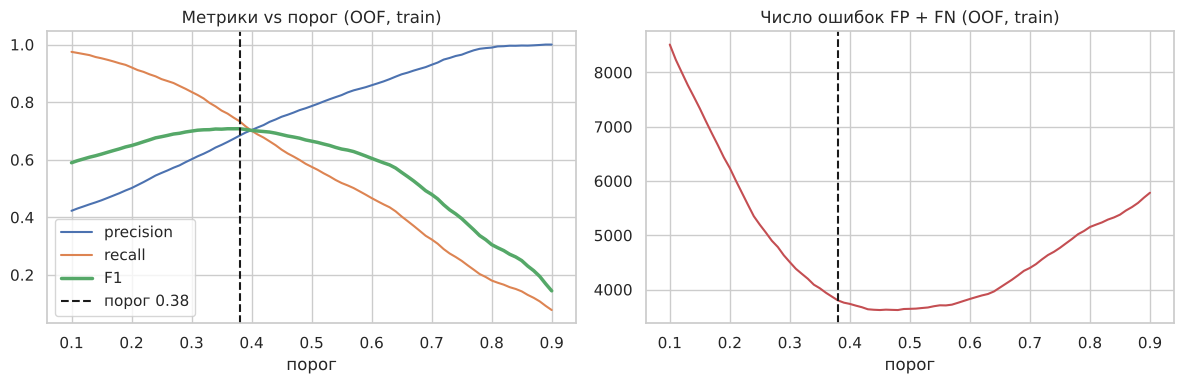

In [16]:
best_name = max(cv_f1_mean, key=cv_f1_mean.get)
best_pipe = models[best_name]
print("F1 по CV:", {k: round(v, 4) for k, v in cv_f1_mean.items()}, "-> выбираем:", best_name)

# out-of-fold вероятности лучшей модели на train
oof_proba = cross_val_predict(clone(best_pipe), X_train, y_train, cv=skf, method="predict_proba")[:, 1]

thresholds = np.linspace(0.1, 0.9, 81)
f1s = np.array([f1_score(y_train, oof_proba >= t) for t in thresholds])
errs = np.array([((oof_proba >= t) != y_train).sum() for t in thresholds])

def best_threshold(y_true, proba, grid=thresholds):
    scores = [f1_score(y_true, proba >= t) for t in grid]
    return float(grid[int(np.argmax(scores))])

thr = best_threshold(y_train, oof_proba)
print(f"Лучший порог по F1 (OOF): {thr:.2f} | F1 при 0.50: {f1_score(y_train, oof_proba >= .5):.4f} | при {thr:.2f}: {f1_score(y_train, oof_proba >= thr):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
prec = [precision_score(y_train, oof_proba >= t) for t in thresholds]
rec = [recall_score(y_train, oof_proba >= t) for t in thresholds]
ax[0].plot(thresholds, prec, label="precision"); ax[0].plot(thresholds, rec, label="recall"); ax[0].plot(thresholds, f1s, label="F1", lw=2.5)
ax[0].axvline(thr, color="k", ls="--", label=f"порог {thr:.2f}"); ax[0].set_xlabel("порог"); ax[0].legend(); ax[0].set_title("Метрики vs порог (OOF, train)")
ax[1].plot(thresholds, errs, color="C3"); ax[1].axvline(thr, color="k", ls="--"); ax[1].set_xlabel("порог"); ax[1].set_title("Число ошибок FP + FN (OOF, train)")
plt.tight_layout(); plt.show()

,порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,FP,FN,FP+FN
вариант,,,,,,,,,,
всегда '<=50K' (база),0.50,0.759,0.000,0.000,0.000,0.500,0.241,0,1568,1568
"RandomForest, порог 0.50",0.50,0.871,0.808,0.608,0.694,0.922,0.821,226,615,841
"RandomForest, порог 0.38 (подобран на OOF)",0.38,0.863,0.697,0.763,0.729,0.922,0.821,520,371,891


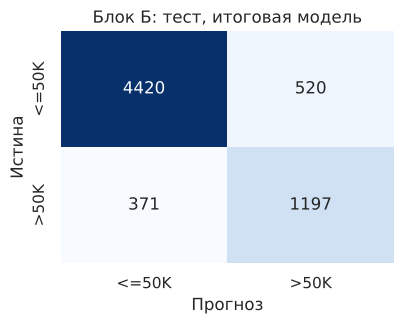

In [17]:
# Финал: обучаем на всём train, один раз оцениваем на отложенном тесте
final_b = clone(best_pipe).fit(X_train, y_train)
proba_test = final_b.predict_proba(X_test)[:, 1]

def report(y_true, proba, thr, label):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"вариант": label, "порог": round(thr, 2), "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred), "recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred), "ROC-AUC": roc_auc_score(y_true, proba),
            "PR-AUC": average_precision_score(y_true, proba), "FP": fp, "FN": fn, "FP+FN": fp + fn}

rep_b = pd.DataFrame([
    report(y_test, np.zeros(len(y_test)), 0.5, "всегда '<=50K' (база)"),
    report(y_test, proba_test, 0.5, f"{best_name}, порог 0.50"),
    report(y_test, proba_test, thr, f"{best_name}, порог {thr:.2f} (подобран на OOF)"),
]).set_index("вариант")
rep_b.loc[rep_b.index[0], ["ROC-AUC", "PR-AUC"]] = [0.5, y_test.mean()]
display(rep_b.round(3))

pred_b = (proba_test >= thr).astype(int)
fig, ax = plt.subplots(figsize=(4.2, 3.4))
sns.heatmap(confusion_matrix(y_test, pred_b), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["<=50K", ">50K"], yticklabels=["<=50K", ">50K"])
ax.set_xlabel("Прогноз"); ax.set_ylabel("Истина"); ax.set_title("Блок Б: тест, итоговая модель")
plt.tight_layout(); plt.show()

### Вывод по блоку Б: можно ли отдавать модель заказчику

**Результаты.**

| | LogisticRegression | RandomForest |
|---|---|---|
| F1 (CV, 5 фолдов, train) | 0.640 ± 0.004 | **0.664 ± 0.015** |
| ROC-AUC (CV) | 0.897 | **0.916** |
| PR-AUC (CV) | 0.732 | **0.800** |

Выбрана **RandomForest** (лучше по F1, ROC-AUC и PR-AUC на всех метриках ранжирования). Порог подобран по out-of-fold предсказаниям train: **0.38** (F1 на OOF вырос с 0.665 до 0.708).

**Отложенный тест (один раз, итоговая модель):**

| вариант | accuracy | precision | recall | F1 | FP | FN | FP+FN |
|---|---|---|---|---|---|---|---|
| всегда `<=50K` | 0.759 | 0 | 0 | 0 | 0 | 1568 | 1568 |
| RandomForest, порог 0.50 | 0.871 | 0.808 | 0.608 | 0.694 | 226 | 615 | 841 |
| **RandomForest, порог 0.38** | 0.863 | 0.697 | **0.763** | **0.729** | 520 | 371 | 891 |

ROC-AUC на тесте 0.922. Значения на тесте (F1 0.729) близки к OOF на train (0.708), то есть признаков утечки или подгонки под тест нет. По сравнению с блоком А доля найденных людей с доходом >50K выросла с 61,7% до **76,3%**.

**Метрика и порог.** F1 по классу `>50K`: сопоставимая цена ошибок означает, что нельзя оптимизировать только precision или только recall, а accuracy скрывает перекос классов. Порог 0.38 выбран, чтобы лучше находить состоятельных клиентов (recall 0.76), ценой более частых ошибочных предложений (precision 0.70). Важная оговорка: на этом пороге общее число ошибок FP + FN выше, чем при 0.50 (891 против 841). Если у банка стоимость одного ложного предложения и одного пропущенного клиента **в точности равны**, лучше брать порог около 0.5; если пропуск обходится дороже рассылки, порог ещё ниже. Правильный порог определяется реальными деньгами, а их у нас нет.

**Можно ли отдавать модель?** Можно как **скоринг для пилота** (ранжирование клиентов и подготовка рассылки), но **не как автоматическое решение** без оговорок:

1. Данные: перепись США 1994 года, а не клиенты банка. Распределение у реальных клиентов будет другим, нужна проверка на данных банка.
2. Целевая переменная — доход, а не платёжеспособность или риск дефолта. Это не кредитный скоринг.
3. Порог нужно пересчитать по реальной стоимости ложного предложения и упущенного клиента.
4. Модель использует `sex`, `race`, `native.country`, `marital.status`, `relationship`. Для кредитных решений это недопустимо или спорно (подробнее в блоке В).
5. Около 24% состоятельных людей всё равно пропускается, а около 30% предложений уходит людям с доходом ≤50K. Для рассылки это допустимо, для отказов нет.
6. Рекомендуется пилот с A/B-проверкой и регулярный мониторинг качества.

---
# Блок В. Продвинутый

## В.1. Все проблемы данных и потенциальные утечки: что, как нашли, что сделали

Сначала подтверждаем цифрами то, что ещё не показано выше (дубликаты уже в Б.0, пропуски и «заглушки» в Б.1).

In [18]:
# (а) capital.gain тесно связан с самим доходом: проверяем, насколько
bins = pd.cut(eda["capital.gain"], [-1, 0, 3000, 5000, 7000, 99998, 99999],
              labels=["0", "1–3000", "3001–5000", "5001–7000", "7001–99998", "99999"])
print("Доля >50K по размеру capital.gain (train):")
display(eda.groupby(bins)["income"].agg(["mean", "size"]).rename(columns={"mean": "доля >50K", "size": "n"}).round(3).T)

# (б) вес capital.gain/loss в качестве модели: CV F1 с ними и без них
def cv_f1_cfg(**kw):
    pipe = make_pipe(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), **kw)
    r = cross_validate(pipe, X_train, y_train, cv=skf, scoring=["f1", "roc_auc"])
    return r["test_f1"].mean(), r["test_roc_auc"].mean()

f_all, a_all = cv_f1_cfg()
f_nocap, a_nocap = cv_f1_cfg(money=[])
print(f"\nLogReg, CV: с capital.gain/loss  F1={f_all:.3f}, ROC-AUC={a_all:.3f}")
print(f"           без capital.gain/loss F1={f_nocap:.3f}, ROC-AUC={a_nocap:.3f}")

Доля >50K по размеру capital.gain (train):


capital.gain,0,1–3000,3001–5000,5001–7000,7001–99998,99999
доля >50K,0.207,0.0,0.309,0.459,0.982,1.0
n,23855.000,381.0,488.000,194.000,987.000,124.0



LogReg, CV: с capital.gain/loss  F1=0.640, ROC-AUC=0.897
           без capital.gain/loss F1=0.614, ROC-AUC=0.884


### Демонстрация утечки через ресемплинг до кросс-валидации

Если сначала «размножить» класс `>50K` (oversampling) на всём train, а потом делать CV, копии одной и той же записи окажутся и в обучающей, и в валидационной частях фолда. Метрика завышается, хотя модель на новых людях лучше не стала.

In [19]:
def random_oversample(X_, y_, seed=RANDOM_STATE):
    # дублируем строки меньшего класса (с возвращением) до равенства классов
    rng = np.random.RandomState(seed)
    pos, neg = np.where(y_.values == 1)[0], np.where(y_.values == 0)[0]
    extra = rng.choice(pos, size=len(neg) - len(pos), replace=True)
    idx = np.concatenate([np.arange(len(y_)), extra])
    return X_.iloc[idx], y_.iloc[idx]

rf_demo = make_pipe(RandomForestClassifier(n_estimators=60, min_samples_leaf=1, n_jobs=-1, random_state=RANDOM_STATE))

# НЕПРАВИЛЬНО: ресемплинг до CV
X_over, y_over = random_oversample(X_train, y_train)
wrong = cross_validate(rf_demo, X_over, y_over, cv=skf, scoring="f1")["test_score"]

# ПРАВИЛЬНО: ресемплинг только внутри обучающей части каждого фолда, валидация на нетронутых данных
right = []
for tr, va in skf.split(X_train, y_train):
    Xo, yo = random_oversample(X_train.iloc[tr], y_train.iloc[tr])
    m = clone(rf_demo).fit(Xo, yo)
    right.append(f1_score(y_train.iloc[va], m.predict(X_train.iloc[va])))

print(f"F1 при ресемплинге ДО CV (утечка):  {wrong.mean():.3f}")
print(f"F1 при ресемплинге ВНУТРИ фолдов:   {np.mean(right):.3f}")

F1 при ресемплинге ДО CV (утечка):  0.920
F1 при ресемплинге ВНУТРИ фолдов:   0.665


**Сводная таблица проблем и утечек**

| # | Проблема / риск утечки | Как нашли | Что сделали |
|---|---|---|---|
| 1 | Пропуски `?` (`workclass`, `occupation`, `native.country`) не распознаются pandas | в файле значение `?`, `info()` показал 0 пропусков до `na_values` | `na_values="?"`, импутация модой внутри Pipeline, fit только на train |
| 2 | Утечка через предобработку: импутер/скейлер/энкодер обучены на всех данных | риск по построению | split до всего; все шаги в `Pipeline`/`ColumnTransformer`, fit на фолде |
| 3 | Полные дубликаты (попадание копий в train и test) | `df.duplicated()`; пересечение train/test в блоке А | удалены до разбиения |
| 4 | Тест участвует в выборе порога / модели | риск по построению | порог — по OOF на train, модель — по CV; тест один раз в конце |
| 5 | Ресемплинг до CV (копии в валидации) | эксперимент выше | ресемплинг только внутри обучающей части фолда |
| 6 | `capital.gain` (особенно 99999) почти однозначно определяет `>50K` | таблица долей по корзинам | вероятно, компонент самого дохода (признак почти «подсказывает» ответ); оставляем с оговоркой и показываем модель без него |
| 7 | `fnlwgt` — вес записи переписи, не характеристика человека | EDA, низкая взаимная информация, абляция CV | удалён |
| 8 | `education` дублирует `education.num` | соответствие 1:1 | удалён `education` |
| 9 | Top-coding (`age=90`, `hours=99`, `capital.gain=99999`) | `value_counts`, boxplot | оставлены как есть, отмечены как цензурированные |
| 10 | `relationship`, `marital.status`, `sex`, `race`, `native.country` — защищённые признаки или их прокси | смысл признаков, crosstab | см. В.4–В.5 |

## В.2. Методы против дисбаланса **внутри** кросс-валидации

Сравниваем на лучшей модели из блока Б пять вариантов. Все преобразования выполняются **внутри обучающей части каждого фолда**:

1. **Без обработки** (порог 0.5)
2. **`class_weight="balanced"`** (штраф за ошибку на редком классе)
3. **Random oversampling** класса `>50K`
4. **Random undersampling** класса `<=50K`
5. **Подбор порога** (порог выбирается по внутреннему OOF обучающей части фолда, на валидационной части фолда не подбирается)

Метрика заказчика — F1 по классу `>50K`; смотрим ещё precision, recall и FP + FN.

In [20]:
def random_undersample(X_, y_, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    pos, neg = np.where(y_.values == 1)[0], np.where(y_.values == 0)[0]
    keep = np.concatenate([pos, rng.choice(neg, size=len(pos), replace=False)])
    return X_.iloc[keep], y_.iloc[keep]

def fit_strategy(strategy, Xtr, ytr, base=None):
    # Обучает модель выбранным способом ТОЛЬКО на (Xtr, ytr). Возвращает (модель, порог)
    base = base if base is not None else best_pipe
    model, thr_ = clone(base), 0.5
    if strategy == "class_weight":
        model.set_params(clf__class_weight="balanced")
    elif strategy == "oversample":
        Xtr, ytr = random_oversample(Xtr, ytr)
    elif strategy == "undersample":
        Xtr, ytr = random_undersample(Xtr, ytr)
    elif strategy == "threshold":
        inner = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
        inner_oof = cross_val_predict(clone(base), Xtr, ytr, cv=inner, method="predict_proba")[:, 1]
        thr_ = best_threshold(ytr, inner_oof)
    return model.fit(Xtr, ytr), thr_

strategies = {"none": "Без обработки", "class_weight": "class_weight='balanced'",
              "oversample": "Oversampling", "undersample": "Undersampling", "threshold": "Подбор порога"}

rows, fold_f1 = [], {}
for key, title in strategies.items():
    f1l, pl, rl, el = [], [], [], []
    for tr, va in skf.split(X_train, y_train):
        model, t_ = fit_strategy(key, X_train.iloc[tr], y_train.iloc[tr])
        pr = (model.predict_proba(X_train.iloc[va])[:, 1] >= t_).astype(int)
        yt = y_train.iloc[va]
        f1l.append(f1_score(yt, pr)); pl.append(precision_score(yt, pr)); rl.append(recall_score(yt, pr)); el.append((pr != yt).sum())
    fold_f1[key] = f1l
    rows.append({"метод": title, "F1": np.mean(f1l), "± F1": np.std(f1l), "precision": np.mean(pl),
                 "recall": np.mean(rl), "FP+FN (в среднем на фолд)": np.mean(el)})
imb = pd.DataFrame(rows).set_index("метод")
display(imb.round(3))
best_strategy = max(fold_f1, key=lambda k: np.mean(fold_f1[k]))
print("Лучший по F1 в CV:", strategies[best_strategy])

,F1,± F1,precision,recall,FP+FN (в среднем на фолд)
метод,,,,,
Без обработки,0.664,0.015,0.786,0.575,728.8
class_weight='balanced',0.687,0.006,0.568,0.871,994.6
Oversampling,0.690,0.008,0.574,0.863,974.2
Undersampling,0.680,0.007,0.555,0.879,1035.8
Подбор порога,0.707,0.006,0.668,0.752,780.8


Лучший по F1 в CV: Подбор порога


In [21]:
# Финальная модель блока В: лучший метод, обучен на всём train, один раз оценён на тесте
final_v, thr_v = fit_strategy(best_strategy, X_train, y_train)
proba_v = final_v.predict_proba(X_test)[:, 1]
rep_v = pd.DataFrame([
    report(y_test, proba_test, thr, f"Блок Б: {best_name} + порог"),
    report(y_test, proba_v, thr_v, f"Блок В: {strategies[best_strategy]}"),
]).set_index("вариант")
display(rep_v.round(3))
pred_v = (proba_v >= thr_v).astype(int)

,порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,FP,FN,FP+FN
вариант,,,,,,,,,,
Блок Б: RandomForest + порог,0.38,0.863,0.697,0.763,0.729,0.922,0.821,520,371,891
Блок В: Подбор порога,0.38,0.863,0.697,0.763,0.729,0.922,0.821,520,371,891


## В.3. Анализ ошибок: на каких группах людей модель ошибается чаще

Считаем на тесте для итоговой модели блока В. **FNR** (доля пропущенных богатых) = FN / (TP + FN), **FPR** (доля ошибочных «предложений») = FP / (FP + TN). Если значения сильно различаются между группами, модель работает для них по-разному.

In [22]:
err = X_test.copy()
err["y"], err["pred"] = y_test.values, pred_v
err["age_group"] = pd.cut(err["age"], [0, 25, 35, 45, 55, 65, 100], labels=["≤25", "26–35", "36–45", "46–55", "56–65", "65+"])
err["hours_group"] = pd.cut(err["hours.per.week"], [0, 30, 40, 50, 100], labels=["≤30", "31–40", "41–50", ">50"])
err["education_group"] = pd.cut(err["education.num"], [0, 8, 9, 12, 13, 16],
                                labels=["ниже школы", "школа", "колледж", "бакалавр", "магистр+"])
err["country_group"] = np.where(err["native.country"].isna(), "нет данных",
                                np.where(err["native.country"] == "United-States", "США", "другая"))
for c in ["workclass", "occupation"]:
    err[c] = err[c].fillna("нет данных")

def group_report(col, min_n=30):
    g = err.groupby(col, observed=True)
    out = pd.DataFrame({
        "n": g.size(),
        "доля >50K": g["y"].mean(),
        "доля предсказанных >50K": g["pred"].mean(),
        "FNR": g.apply(lambda d: ((d.pred == 0) & (d.y == 1)).sum() / max((d.y == 1).sum(), 1)),
        "FPR": g.apply(lambda d: ((d.pred == 1) & (d.y == 0)).sum() / max((d.y == 0).sum(), 1)),
        "ошибок, %": g.apply(lambda d: (d.pred != d.y).mean() * 100),
    })
    return out[out["n"] >= min_n].round(3)

overall_fnr = ((err.pred == 0) & (err.y == 1)).sum() / (err.y == 1).sum()
overall_fpr = ((err.pred == 1) & (err.y == 0)).sum() / (err.y == 0).sum()
print(f"Всего на тесте: FNR = {overall_fnr:.3f}, FPR = {overall_fpr:.3f}, ошибок = {(err.pred != err.y).mean():.1%}")

for col in ["sex", "race", "age_group", "marital.status", "education_group", "hours_group", "country_group"]:
    print(f"\n— {col}")
    display(group_report(col))

Всего на тесте: FNR = 0.237, FPR = 0.105, ошибок = 13.7%

— sex


,n,доля >50K,доля предсказанных >50K,FNR,FPR,"ошибок, %"
sex,,,,,,
Female,2130,0.119,0.112,0.311,0.034,6.667
Male,4378,0.300,0.338,0.222,0.149,17.108



— race


,n,доля >50K,доля предсказанных >50K,FNR,FPR,"ошибок, %"
race,,,,,,
Amer-Indian-Eskimo,66,0.136,0.091,0.667,0.053,13.636
Asian-Pac-Islander,208,0.264,0.337,0.218,0.176,18.750
Black,644,0.135,0.112,0.345,0.027,6.988
Other,65,0.062,0.077,0.000,0.016,1.538
White,5525,0.256,0.283,0.229,0.115,14.425



— age_group


,n,доля >50K,доля предсказанных >50K,FNR,FPR,"ошибок, %"
age_group,,,,,,
≤25,1230,0.020,0.020,0.520,0.010,2.033
26–35,1761,0.181,0.193,0.339,0.089,13.458
36–45,1562,0.353,0.389,0.200,0.164,17.670
46–55,1132,0.387,0.425,0.194,0.184,18.816
56–65,594,0.313,0.350,0.258,0.172,19.865
65+,229,0.214,0.249,0.143,0.083,9.607


... (4 outputs left out)


— hours_group


,n,доля >50K,доля предсказанных >50K,FNR,FPR,"ошибок, %"
hours_group,,,,,,
≤30,1022,0.074,0.102,0.237,0.049,6.262
31–40,3566,0.197,0.200,0.287,0.074,11.610
41–50,1207,0.405,0.457,0.186,0.214,20.298
>50,713,0.421,0.488,0.200,0.262,23.562



— country_group


,n,доля >50K,доля предсказанных >50K,FNR,FPR,"ошибок, %"
country_group,,,,,,
США,5817,0.248,0.269,0.239,0.107,13.959
другая,564,0.172,0.200,0.237,0.084,10.993
нет данных,127,0.236,0.307,0.133,0.134,13.386


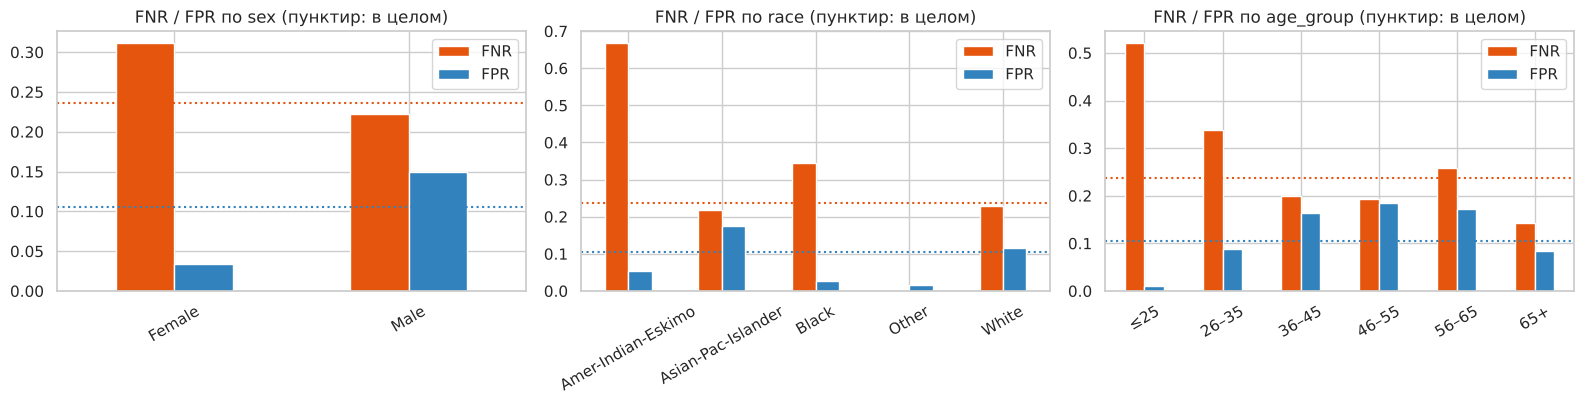

In [23]:
# Визуализация: FNR и FPR по ключевым группам
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, ["sex", "race", "age_group"]):
    t = group_report(col)[["FNR", "FPR"]]
    t.plot.bar(ax=ax, rot=30, color=["#e6550d", "#3182bd"])
    ax.axhline(overall_fnr, color="#e6550d", ls=":"); ax.axhline(overall_fpr, color="#3182bd", ls=":")
    ax.set_title(f"FNR / FPR по {col} (пунктир: в целом)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [24]:
# Самые проблемные профессии (где достаточно людей и реальных >50K, чтобы оценка была не шумом)
occ = group_report("occupation", min_n=50)
occ = occ[(occ["доля >50K"] * occ["n"]) >= 15]
print("Профессии с самой высокой долей пропущенных высокодоходных (FNR):")
display(occ.sort_values("FNR", ascending=False).head(5))
print("Профессии с самой высокой долей ошибочных «предложений» (FPR):")
display(occ.sort_values("FPR", ascending=False).head(5))

# Разница между мужчинами и женщинами: охват и пропуск
sx = group_report("sex")
print("\nРазрыв по полу: TPR(М) - TPR(Ж) = %.3f | доля предсказанных >50K: М %.3f, Ж %.3f" % (
    (1 - sx.loc["Male", "FNR"]) - (1 - sx.loc["Female", "FNR"]),
    sx.loc["Male", "доля предсказанных >50K"], sx.loc["Female", "доля предсказанных >50K"]))

Профессии с самой высокой долей пропущенных высокодоходных (FNR):


,n,доля >50K,доля предсказанных >50K,FNR,FPR,"ошибок, %"
occupation,,,,,,
Other-service,668,0.030,0.007,0.850,0.003,2.844
Transport-moving,334,0.183,0.132,0.656,0.084,18.862
Farming-fishing,209,0.096,0.067,0.600,0.032,8.612
Machine-op-inspct,402,0.124,0.085,0.580,0.037,10.448
Craft-repair,814,0.220,0.193,0.447,0.091,16.953


Профессии с самой высокой долей ошибочных «предложений» (FPR):


,n,доля >50K,доля предсказанных >50K,FNR,FPR,"ошибок, %"
occupation,,,,,,
Exec-managerial,810,0.493,0.589,0.108,0.294,20.247
Prof-specialty,826,0.441,0.524,0.099,0.227,17.070
Tech-support,189,0.333,0.423,0.175,0.222,20.635
Protective-serv,118,0.339,0.356,0.275,0.167,20.339
Sales,734,0.289,0.327,0.222,0.144,16.621



Разрыв по полу: TPR(М) - TPR(Ж) = 0.089 | доля предсказанных >50K: М 0.338, Ж 0.112


### Вывод по анализу ошибок

В целом на тесте: FNR = 0.237 (пропущено 23,7% высокодоходных), FPR = 0.105 (10,5% низкодоходных получили предложение), ошибок 13,7%.

**Где модель ошибается заметно чаще** (малые группы n < 100 ненадёжны, оценки шумят):

- **Пол.** У женщин FNR **0.311** против 0.222 у мужчин: высокодоходных женщин пропускают чаще. Зато у мужчин FPR **0.149** против 0.034: мужчины чаще получают ложное предложение. Модель предсказывает «>50K» для 33,8% мужчин и для 11,2% женщин при фактических 30,0% и 11,9%. Она копирует различие базовых долей в данных.
- **Раса.** Для `Black` FNR 0.345 (при FPR 0.027), для `Asian-Pac-Islander` FPR 0.176. У `Amer-Indian-Eskimo` FNR 0.667, но это всего 66 человек (около 9 с доходом >50K), вывод ненадёжен.
- **Возраст.** До 25 лет FNR **0.52**, в 26–35 лет 0.34: молодых высокодоходных модель не видит. В 36–65 лет FPR 0.16–0.18, ошибок больше всего (около 18–20%).
- **Семейное положение.** `Never-married` и `Divorced`: FNR 0.60 и 0.67. У `Married-civ-spouse` FPR **0.30**, ошибок 24,4% — максимум среди групп. Модель считает «женат/замужем» сильным признаком высокого дохода.
- **Образование и профессия.** Образование ниже школы: FNR 0.68; магистр и выше: FPR **0.37**. По профессиям: `Other-service` FNR 0.85, `Transport-moving` 0.66; `Exec-managerial` FPR 0.29.
- **Часы работы.** При более 50 часов в неделю ошибок больше всего (23,6%), в основном ложные предложения.
- **Страна происхождения.** Заметной разницы нет (FNR 0.239 у США и 0.237 у остальных).

**Закономерность:** модель опирается на «групповые» признаки (семейное положение, образование, профессия, часы, пол). Ошибки сосредоточены там, где человек не похож на типичного представителя своей группы: богатые из «бедных» групп пропускаются (FN), бедные из «богатых» групп получают предложение (FP). Для женщин, молодых и людей без семьи это означает меньше шансов получить предложение даже при высоком доходе.

## В.4. Допустимость признаков для кредитного решения и ограничения решения

Ниже проверка «цены» отказа от спорных признаков: модель переобучается без них (CV на train, тот же способ, что и выше).

In [25]:
PROTECTED = ["sex", "race", "native.country", "marital.status", "relationship"]

configs = {
    "Все признаки (после Б)": dict(),
    "Без защищённых и их прокси (sex, race, native.country, marital.status, relationship)":
        dict(cat=[c for c in CAT if c not in PROTECTED]),
    "Без защищённых + без capital.gain/loss":
        dict(cat=[c for c in CAT if c not in PROTECTED], money=[]),
    "Без защищённых + без capital.* + без age":
        dict(num=["education.num", "hours.per.week"], cat=[c for c in CAT if c not in PROTECTED], money=[]),
}
rows = []
for title, kw in configs.items():
    pipe = make_pipe(clone(best_pipe.named_steps["clf"]), **kw)
    # для честного сравнения наборов признаков берём один и тот же порог 0.5
    r = cross_validate(pipe, X_train, y_train, cv=skf, scoring=["f1", "roc_auc"])
    rows.append({"набор признаков": title, "F1 (порог 0.5)": r["test_f1"].mean(), "ROC-AUC": r["test_roc_auc"].mean()})
abl = pd.DataFrame(rows).set_index("набор признаков")
display(abl.round(3))

,F1 (порог 0.5),ROC-AUC
набор признаков,,
Все признаки (после Б),0.664,0.916
"Без защищённых и их прокси (sex, race, native.country, marital.status, relationship)",0.580,0.869
Без защищённых + без capital.gain/loss,0.506,0.832
Без защищённых + без capital.* + без age,0.435,0.788


### Ограничения решения

**Цена отказа от спорных признаков (CV на train, порог 0.5):**

| набор признаков | F1 | ROC-AUC |
|---|---|---|
| все признаки после Б | 0.664 | 0.916 |
| без `sex, race, native.country, marital.status, relationship` | 0.580 | 0.869 |
| то же + без `capital.gain/loss` | 0.506 | 0.832 |
| то же + без `age` | 0.435 | 0.788 |

Без защищённых признаков и их прокси ROC-AUC падает на 0.047, это заметная потеря. Значит, часть качества модели обеспечивают именно признаки, которые нельзя использовать в кредитном решении (в первую очередь `marital.status` и `relationship`).

**Допустимость признаков для кредитного решения** (ориентир — американское законодательство о равных кредитных возможностях ECOA / Regulation B, так как данные американские; в вашей юрисдикции правила другие, это нужно проверить с юристом банка; не юридическая консультация):

| Признак | Оценка | Решение |
|---|---|---|
| `sex` | прямо защищённый признак | **убрать** |
| `race` | прямо защищённый признак | **убрать** |
| `native.country` | национальное происхождение | **убрать** (к тому же 90% — США, признак почти не информативен) |
| `marital.status` | семейное положение, защищено | **убрать** |
| `relationship` | `Husband`/`Wife` однозначно кодируют пол и брак (см. EDA) | **убрать** |
| `age` | допустим только с оговорками, зависит от юрисдикции | использовать осторожно, проверить юристом |
| `fnlwgt` | вес записи переписи, не характеристика человека | **убрать** (уже убран) |
| `education.num`, `workclass`, `occupation`, `hours.per.week` | допустимы, но могут быть **прокси** пола и возраста | оставить, мониторить ошибки по группам |
| `capital.gain`, `capital.loss` | вероятно, часть самого дохода; у банка может не быть проверяемых данных | оставить только если их можно реально получить и подтвердить на момент решения |

Важно: простое удаление `sex` и `race` не гарантирует отсутствия дискриминации, потому что остаются прокси (`occupation`, `hours.per.week`, `education.num`). После удаления нужно **повторно** посмотреть разбивку ошибок по группам, как в В.3.

**Ограничения решения в целом:**

1. **Данные устарели и из другой популяции:** перепись США 1994 года. Порог $50K в тех деньгах не равен сегодняшнему. Клиенты банка отличаются от населения.
2. **Цель — не то, что нужно банку:** доход ≠ платёжеспособность. Модель не оценивает риск дефолта и не заменяет кредитный скоринг.
3. **Стоимость ошибок не измерена:** «сопоставима» — это не число. Порог должен быть подобран по реальным затратам на рассылку и прибыли с клиента.
4. **Признаки с цензурой:** `age = 90`, `hours = 99`, `capital.gain = 99999` — «потолки», реальные значения неизвестны.
5. **Малые группы:** для редких категорий (малое число людей, например `Amer-Indian-Eskimo`) оценки ошибок нестабильны.
6. **Не использовалась настройка гиперпараметров и калибровка вероятностей.** Порог подобран по неоткалиброванным вероятностям случайного леса, значит, выбранная точка может «плыть» на других данных.
7. **Использование:** модель подходит для приоритизации маркетинговой рассылки, но не для отказа в кредите без проверки человеком и аудита справедливости.

---
## Итог

Всё, что описано в трёх блоках, воспроизводится запуском ячеек сверху вниз (`Kernel -> Restart & Run All`). Случайность зафиксирована `random_state=42`.